# PREPROCESAMIENTO

In [576]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats 
import missingno as msno
import sklearn as sk
from sklearn.impute import KNNImputer
from sklearn.preprocessing import PolynomialFeatures, RobustScaler, StandardScaler, PowerTransformer
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestRegressor
from feature_engine.outliers import Winsorizer


## Carga de datos del dataset completo

In [577]:
FILENAME = "dataset_consolidado_complete.csv"
datapath_completo = os.path.join("..","data","clean",FILENAME)
df_completo = pd.read_csv(datapath_completo)


C:\Users\ireni\AppData\Local\Temp\ipykernel_25592\615093942.py:3: DtypeWarning: Columns (153: Nivel Silo Bagazo Norte (1), 177: KW Trafo 8, 335: Totalizador Bba P1, 336: Totalizador Bba P2, 337: Totalizador Bba P4, 338: Totalizador Bba Envasado, 339: Totalizador Bba P51) have mixed types. Specify dtype option on import or set low_memory=False.
  df_completo = pd.read_csv(datapath_completo)


In [578]:
df_completo = df_completo.replace(' ', np.nan)
columnas_numericas = ~df_completo.columns.isin(["DIA", "HORA"])
df_completo.loc[:, columnas_numericas] = (
    df_completo.loc[:, columnas_numericas]
    .apply(pd.to_numeric, errors="coerce")
)

## Creacion del dataframe diario

Para la creación del dataset diario se tuvo en cuenta: los días completos (aquellos que llegaron a las 23:59 horas) y los días con reinicio en el consumo de frío.

Además, mediante conocimiento del dominio y EDA se filtraron como primera pasada algunas variables.  

In [579]:
df_completo = df_completo.sort_values(["DIA", "HORA"])
df_temp = df_completo.groupby('DIA').tail(1).reset_index(drop=True)
hora_cierre = '23:59:00'
df_diario = df_temp[df_temp['HORA'] == hora_cierre].copy()


dias_eliminados = len(df_temp) - len(df_diario)
print(f"Se eliminaron {dias_eliminados} días incompletos que no llegaron a las 23:59.")

#días donde el target no se reinicio a las 00:00 (Se obtuvieron del eda)
dias_sin_reinicio = df_completo[(df_completo["HORA"] == "00:00:00") & (df_completo["Frio (Kw)"] != 0)]["DIA"]
df_diario = df_diario.drop(index= df_diario[df_diario["DIA"].isin(dias_sin_reinicio)].index)
df_diario = df_diario[df_diario["Frio (Kw)"] <= 500000].copy()


fecha_siguiente = pd.to_datetime(df_diario["DIA"].shift(-1))
fecha_actual = pd.to_datetime(df_diario["DIA"])
dias_consecutivos = (fecha_siguiente == fecha_actual + pd.Timedelta(days=1))
df_diario["target_Frio_kW_next"] = (df_diario["Frio (Kw)"].shift(-1))
df_diario.loc[~dias_consecutivos,"target_Frio_kW_next"] = np.nan
df_diario = df_diario.dropna(subset=["target_Frio_kW_next"]).copy()            


#Features a utilizar (conocimiento del dominio)

features_a_utilizar = [
    "DIA",
    "KW Mycom 1",
    "KW Mycom 2",
    "KW Mycom 3",
    "KW Mycom 4",
    "KW Mycom 5",
    "KW Mycom 6",
    "KW Mycom 7",
    "EE Frio / Hl",
    "KW Bba Glicol Sala MAq",
    "KW Bba Glicol Bod",
    "KW Enfr Agua Cocina",
    "Hl de Mosto",
    "Hl Producido Bodega",
    "Hl Cerveza Filtrada",
    "Hl Cerveza Envasada",
    "Hl Cerveza Cocina",
    "Elaboracion (Kw)",
    "Bodega (Kw)",
    "Envasado (Kw)",
    "Servicios (Kw)",
    "Frio (Kw)",
    "Agua Planta (Hl)",
    "Agua Helada Cocina",
    "Glicol Paste L3",
    "Temp Tq Intermedio",
    "Gas Planta (Mj)",
    "Vapor Elaboracion (Kg)",
    "Totalizador_Bodega",
    "Totalizador_Tq_Pulmon",
    "Tot Fermantacion_Cocina",
    "Tot Reposo Inferior",
    "Tot  Reposo Superior",
    "Tot  Trasiego",
    "Tot A10/20",
    "Tot A40/240/50/60/Centec/Filtro",
    "Tot  A130/330/430",
    "Tot L3, L4 y Planta de CO2",
    # Variables agregadas tras realizar EDA
    "Agua Cond REC",
    "KW Gral Planta",
    "Planta (Kw)",
    "Sala Maq (Kw)",
    "KW Trafo 4",
    "KW Trafo 5", 
    'KW Trafo 8', 
    'KW Trafo 11', 
    'KW Trafo 12',
    'KW Trafo 9', 
    'KW Trafo 10',
    "KW Cond 5. 6 y 9",
    "Produccion (Hl)",
    "Aire Producido (M3)",
    "Totalizador Sistema Kaeser"
]

df_completo["HORA"] = df_completo["HORA"].astype(str)


target = ["target_Frio_kW_next"]
df_diario = df_diario[features_a_utilizar + target].copy()


Se eliminaron 5 días incompletos que no llegaron a las 23:59.


## Análisis patron de valores faltantes

Con el objetivo de tratar valores faltantes, primero se realizó una inspección del total de nulos en cada una de las variables y su correlación para posteriormente decidir que tratamiento se optará.
 

In [580]:
tabla_nulos = pd.DataFrame(
    {"Valores Nulos": df_diario.isna().sum(),
     "Porcentaje (%)": df_diario.isna().mean() * 100,
    })

tabla_nulos = (
    tabla_nulos.style.set_caption("Resumen de Valores Nulos por Columna")
    .format({"Porcentaje (%)": "{:.2f}%"})
)

display(tabla_nulos)

,Valores Nulos,Porcentaje (%)
DIA,0,0.00%
KW Mycom 1,0,0.00%
KW Mycom 2,0,0.00%
KW Mycom 3,0,0.00%
KW Mycom 4,0,0.00%
KW Mycom 5,0,0.00%
KW Mycom 6,0,0.00%
KW Mycom 7,0,0.00%
EE Frio / Hl,21,1.83%
KW Bba Glicol Sala MAq,0,0.00%


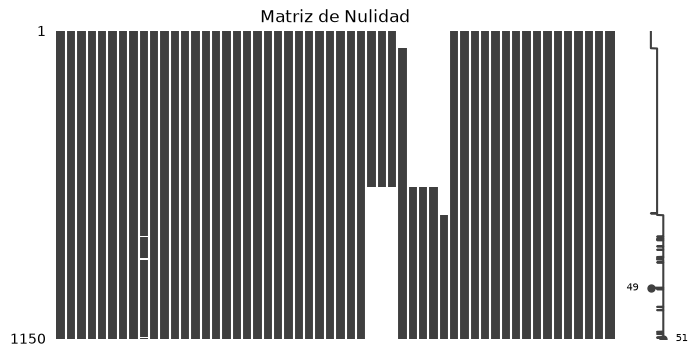

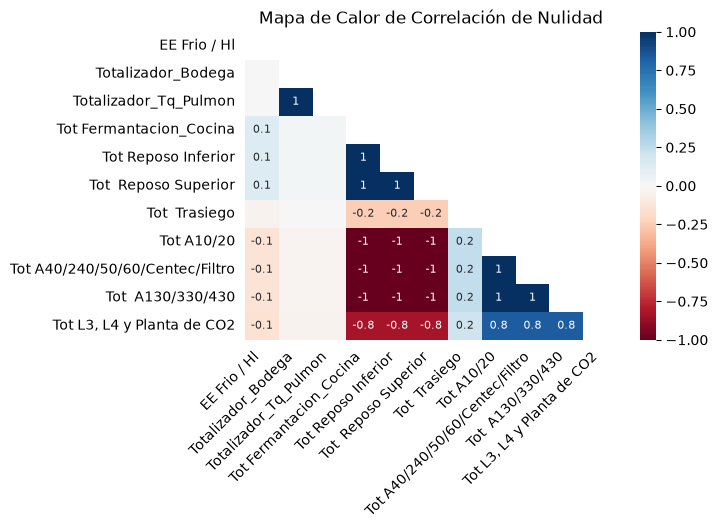

In [581]:
msno.matrix(df_diario, figsize=(8,4), fontsize=8)
plt.title("Matriz de Nulidad")
plt.show()

msno.heatmap(df_diario, figsize=(6,4), fontsize=10)
plt.title("Mapa de Calor de Correlación de Nulidad")
plt.show()

Gracias a la observación de los gráficos, se puede apreciar que las variables con alto porcentajes de valores nulos además presentan una gran correlación de nulidad entre ellas. 
Aquelllas variables donde sus valores superan el 40% de valores nulos se optó por eliminarlas.

In [582]:
pd.set_option("display.max_columns", None)
display(df_diario)

,DIA,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,EE Frio / Hl,KW Bba Glicol Sala MAq,KW Bba Glicol Bod,KW Enfr Agua Cocina,Hl de Mosto,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza Cocina,Elaboracion (Kw),Bodega (Kw),Envasado (Kw),Servicios (Kw),Frio (Kw),Agua Planta (Hl),Agua Helada Cocina,Glicol Paste L3,Temp Tq Intermedio,Gas Planta (Mj),Vapor Elaboracion (Kg),Totalizador_Bodega,Totalizador_Tq_Pulmon,Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,Tot Trasiego,Tot A10/20,Tot A40/240/50/60/Centec/Filtro,Tot A130/330/430,"Tot L3, L4 y Planta de CO2",Agua Cond REC,KW Gral Planta,Planta (Kw),Sala Maq (Kw),KW Trafo 4,KW Trafo 5,KW Trafo 8,KW Trafo 11,KW Trafo 12,KW Trafo 9,KW Trafo 10,KW Cond 5. 6 y 9,Produccion (Hl),Aire Producido (M3),Totalizador Sistema Kaeser,target_Frio_kW_next
0,2020-07-01,0,3600.0,0.0,0,0.0,1013.0,4342.0,333.139535,467.0,1990.0,0.0,0.0,43.000,0.0,86.0,0.00,2027.25,2968.00,594.0,23848.0,14325.0,10280.000000,0.0,0.0,-3.0,150775.730528,6779.44000,733.3100,1775.0,570.17,6323.06,0.1,NaN,NaN,NaN,NaN,NaN,231.210000,29529.0,27637.270000,17080.0,2636.0,1124.0,1186.56,11920.0,3639.0,1637.75,6046.25,614.0,2398.000000,31871.0,31871.0,23954.0
1,2020-07-02,701,5848.0,1362.0,2238,0.0,1062.0,5641.0,3.419545,777.0,2359.0,5.0,2907.0,7005.025,13361.0,10667.0,3343.05,5391.13,5595.88,16522.0,38033.0,23954.0,13970.000000,3452.0,0.0,1.0,469499.449248,45103.22000,5484.0600,14295.0,694.08,5349.47,0.8,NaN,NaN,NaN,NaN,NaN,284.210000,65592.0,54409.810000,27216.0,5792.0,1654.0,3095.53,18592.0,7248.0,17288.75,10108.13,1073.0,25148.500000,51079.0,51079.0,28268.0
2,2020-07-03,328,5980.0,5356.0,3321,0.0,1043.0,4792.0,3.787626,824.0,2615.0,13.0,4829.0,7463.250,9493.0,10024.0,4902.50,6437.75,6237.50,14818.0,42565.5,28268.0,36300.000000,5495.0,0.0,-1.0,548270.265952,61087.32000,5146.2300,8366.0,400.66,4965.47,0.5,NaN,NaN,NaN,NaN,NaN,297.530000,68039.0,65685.590000,31386.0,6863.0,1665.5,1404.94,18486.0,11349.0,17260.75,9177.75,1083.0,29365.000000,62958.0,62958.0,24246.0
3,2020-07-04,0,6040.0,1407.0,5029,0.0,325.0,4901.0,1.870213,765.0,1891.0,28.0,7828.0,12964.300,8450.0,12223.0,13705.60,5694.25,4810.75,18696.0,39650.0,24246.0,40120.000000,8376.0,0.0,2.0,635538.945472,80588.95000,3575.0800,5081.0,447.89,5040.93,1.0,NaN,NaN,NaN,NaN,NaN,279.630000,69857.0,67098.540000,28070.0,7489.0,1648.0,6043.81,20510.0,7586.0,18709.50,6717.25,1031.0,32150.800000,69435.0,69435.0,29885.0
4,2020-07-05,0,6381.0,2043.0,5501,0.0,2568.0,6222.0,3.354482,786.0,2406.0,21.0,6406.0,8908.975,12894.0,8358.0,9459.95,7148.25,6394.75,14831.0,45385.0,29885.0,38940.000000,7971.0,0.0,-2.0,553697.930928,78034.90000,4823.7500,12559.0,400.06,5690.25,0.2,NaN,NaN,NaN,NaN,NaN,282.030000,73431.0,70600.640000,33463.0,7249.0,1645.0,5820.25,22212.0,8410.0,15220.50,9527.25,1077.0,30793.900000,66431.0,66431.0,24449.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1183,2023-10-20,3549,0.0,0.0,576,1279.0,0.0,960.0,NaN,1198.0,2985.0,0.0,0.0,0.000,1541.0,0.0,0.00,3976.00,4619.00,515.0,20273.0,11931.0,12257.954102,0.0,0.0,0.0,167237.171455,9852.87500,858.6250,2369.0,NaN,NaN,NaN,1458.1875,330.125,1636.750,6879.625,76.40625,85.300781,28064.0,26515.660000,14490.0,2162.0,4143.0,492.0,10640.0,60.0,1900.00,7582.00,323.0,5435.917969,19749.0,19749.0,9481.0
1184,2023-10-21,129,0.0,1736.0,0,1954.0,0.0,196.0,NaN,1041.0,2996.0,0.0,0.0,0.000,0.0,0.0,0.00,2383.00,3119.00,452.0,16977.0,9481.0,7468.889160,0.0,0.0,0.0,131153.378545,6476.84375,0.0000,1649.0,NaN,NaN,NaN,0.0000,232.375,2194.000,6922.250,40.12500,68.298828,22953.0,21627.800000,9793.0,3979.0,4788.0,492.5,3216.0,1754.0,1778.00,5818.00,330.0,2979.067383,15961.0,15961.0,11587.0
1185,2023-10-22,0,0.0,0.0,0,4094.0,0.0,1814.0,2.782861,1344.0,2920.0,0.0,3978.0,4163.700,0.0,1167.0,7160.40,3200.00,2788.00,2758.0,208

In [583]:
df_con_nulos =  df_diario.isna().mean() * 100 
columnas_con_nulos = df_con_nulos[df_con_nulos > 40].index

df_diario = df_diario.drop(columns=columnas_con_nulos)

### Variables Mycoms y Trafos

In [584]:
mycoms = df_diario.columns[df_diario.columns.str.contains("Mycom")]
df_diario["Kw Mycom Mean"] = df_diario.loc[:, mycoms].mean(axis=1, skipna=True)
df_diario = df_diario.drop(columns=mycoms, errors= "ignore")
df_diario.columns

Index(['DIA', 'EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'KW Enfr Agua Cocina', 'Hl de Mosto', 'Hl Producido Bodega',
       'Hl Cerveza Filtrada', 'Hl Cerveza Envasada', 'Hl Cerveza Cocina',
       'Elaboracion (Kw)', 'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)',
       'Frio (Kw)', 'Agua Planta (Hl)', 'Agua Helada Cocina',
       'Glicol Paste L3', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Trafo 4', 'KW Trafo 5', 'KW Trafo 8',
       'KW Trafo 11', 'KW Trafo 12', 'KW Trafo 9', 'KW Trafo 10',
       'KW Cond 5. 6 y 9', 'Produccion (Hl)', 'Aire Producido (M3)',
       'Totalizador Sistema Kaeser', 'target_Frio_kW_next', 'Kw Mycom Mean'],
      dtype='str')

In [585]:
trafos = df_diario.columns[df_diario.columns.str.contains("Trafo")]
df_diario["Kw Trafo Mean"] = df_diario.loc[:, trafos].mean(axis=1, skipna=True) 
df_diario = df_diario.drop(columns=trafos, errors= "ignore")

## Valores con ceros

En el transcurso del EDA, no solamente se observo la existencia de valores nulos en las distintas variables sino que tambien se detectó la presencia de columnas con una gran cantidad de ceros. Es necesario comprender que esto no implica nulidad sin embargo cuando la variable toma en casi su totalidad un unico valor (en este caso cero) la misma no esta brindando información para la predicción del Frío.

Aquellas predictoras en donde mas de la mitad de sus valores son ceros se optó por eliminarlas al ser redundantes para la predicción.

In [586]:
ceros = (df_diario==0).sum().sort_values(ascending=False)/df_diario.shape[0]*100
df_diario = df_diario.drop(columns=ceros[ceros>50].index)

In [587]:
numericas = df_diario.columns[~df_diario.columns.isin(["DIA", "HORA"])]

### Separacion de Datos en train y test

## Tratamiento de nulos


Para aquellas predictoras que aún mantienen valores nulos y no fueron eliminadas, se realizó un tratamiento mediante KNNImputed.

In [588]:
df_numericas = df_diario[numericas].copy()
knn_imputer = KNNImputer(n_neighbors =5)
df_knn_imputed = pd.DataFrame(knn_imputer.fit_transform(df_numericas), columns=df_numericas.columns)


In [589]:
df_knn_imputed["DIA"] = df_diario["DIA"].copy()


In [590]:
df_knn_imputed

,EE Frio / Hl,KW Bba Glicol Sala MAq,KW Bba Glicol Bod,Hl de Mosto,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza Cocina,Elaboracion (Kw),Bodega (Kw),Envasado (Kw),Servicios (Kw),Frio (Kw),Agua Planta (Hl),Temp Tq Intermedio,Gas Planta (Mj),Vapor Elaboracion (Kg),Totalizador_Bodega,Totalizador_Tq_Pulmon,Tot Trasiego,Agua Cond REC,KW Gral Planta,Planta (Kw),Sala Maq (Kw),KW Cond 5. 6 y 9,Produccion (Hl),Aire Producido (M3),Totalizador Sistema Kaeser,target_Frio_kW_next,Kw Mycom Mean,Kw Trafo Mean,DIA
0,333.139535,467.0,1990.0,0.0,43.000,0.0,86.0,0.00,2027.25,2968.00,594.0,23848.0,14325.0,10280.000000,-3.0,150775.730528,6779.44000,733.3100,1775.0,98.33575,231.210000,29529.0,27637.270000,17080.0,614.0,2398.000000,31871.0,31871.0,23954.0,1279.285714,4027.080000,2020-07-01
1,3.419545,777.0,2359.0,2907.0,7005.025,13361.0,10667.0,3343.05,5391.13,5595.88,16522.0,38033.0,23954.0,13970.000000,1.0,469499.449248,45103.22000,5484.0600,14295.0,2092.11000,284.210000,65592.0,54409.810000,27216.0,1073.0,25148.500000,51079.0,51079.0,28268.0,2407.428571,9111.201429,2020-07-02
2,3.787626,824.0,2615.0,4829.0,7463.250,9493.0,10024.0,4902.50,6437.75,6237.50,14818.0,42565.5,28268.0,36300.000000,-1.0,548270.265952,61087.32000,5146.2300,8366.0,1119.12200,297.530000,68039.0,65685.590000,31386.0,1083.0,29365.000000,62958.0,62958.0,24246.0,2974.285714,9458.134286,2020-07-03
3,1.870213,765.0,1891.0,7828.0,12964.300,8450.0,12223.0,13705.60,5694.25,4810.75,18696.0,39650.0,24246.0,40120.000000,2.0,635538.945472,80588.95000,3575.0800,5081.0,1551.25800,279.630000,69857.0,67098.540000,28070.0,1031.0,32150.800000,69435.0,69435.0,29885.0,2528.857143,9814.794286,2020-07-04
4,3.354482,786.0,2406.0,6406.0,8908.975,12894.0,8358.0,9459.95,7148.25,6394.75,14831.0,45385.0,29885.0,38940.000000,-2.0,553697.930928,78034.90000,4823.7500,12559.0,1769.86200,282.030000,73431.0,70600.640000,33463.0,1077.0,30793.900000,66431.0,66431.0,24449.0,3245.000000,10012.000000,2020-07-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1183,79.315336,1198.0,2985.0,0.0,0.000,1541.0,0.0,0.00,3976.00,4619.00,515.0,20273.0,11931.0,12257.954102,0.0,167237.171455,9852.87500,858.6250,2369.0,1458.18750,85.300781,28064.0,26515.660000,14490.0,323.0,5435.917969,19749.0,19749.0,9481.0,909.142857,3854.142857,2023-10-20
1184,76.974643,1041.0,2996.0,0.0,0.000,0.0,0.0,0.00,2383.00,3119.00,452.0,16977.0,9481.0,7468.889160,0.0,131153.378545,6476.84375,0.0000,1649.0,0.00000,68.298828,22953.0,21627.800000,9793.0,330.0,2979.067383,15961.0,15961.0,11587.0,573.571429,3117.928571,2023-10-21
1185,2.782861,1344.0,2920.0,3978.0,4163.700,0.0,1167.0,7160.40,3200.00,2788.00,2758.0,20821.0,11587.0,17313.110352,0.0,295228.456226,35214.46875,7.9375,2863.0,0.00000,67.599609,31956.0,30287.570000,11873.0,328.0,11381.960449,26134.0,26134.0,10123.0,844.000000,4391.071429,2023-10-22
1186,20.765128,1093.0,2983.0,0.0,487.500,0.0,975.0,0.00,2329.00,2882.00,3339.0,18771.0,10123.0,12697.983398,0.0,217570.326705,6922.65625,0.0000,3244.0,0.00000,58.400391,30480.0,28667.480000,10395.0,334.0,5431.079102,22882.0,22882.0,10360.0,657.857143,4142.285714,2023-10-23


## Tratamiento de valores extremos


In [591]:
df_diario_sin_outliers = df_knn_imputed.copy()


for f in numericas: 

    Q1 = df_diario_sin_outliers[f].quantile(0.25)
    Q3 = df_diario_sin_outliers[f].quantile(0.75)
    IQR = Q3 - Q1
    P1 = df_diario_sin_outliers[f].quantile(0.01)
    P99 = df_diario_sin_outliers[f].quantile(0.99)

    limite_inferior = Q1 - 3 * IQR
    limite_superior = Q3 + 3 * IQR
    
    if f == 'target_Frio_kW_next':
        cond_outliers = (df_diario_sin_outliers[f] < limite_inferior) | (df_diario_sin_outliers[f] > limite_superior)
        idx_outliers = df_diario_sin_outliers[cond_outliers].index
        df_diario_sin_outliers.drop(index=idx_outliers, inplace=True, errors='ignore')
        
    else:
        df_diario_sin_outliers.loc[df_diario_sin_outliers[f] < limite_inferior, f] = P1
        df_diario_sin_outliers.loc[df_diario_sin_outliers[f] > limite_superior, f] = P99


## Feature Engineering

### Día de la semana y Indicador de fin de semana (binario).

In [592]:
df_diario_sin_outliers["DIA"] = pd.to_datetime(df_diario_sin_outliers["DIA"])
df_diario_sin_outliers["DIA SEMANA"] = df_diario_sin_outliers["DIA"].dt.dayofweek

<Axes: xlabel='DIA SEMANA', ylabel='target_Frio_kW_next'>

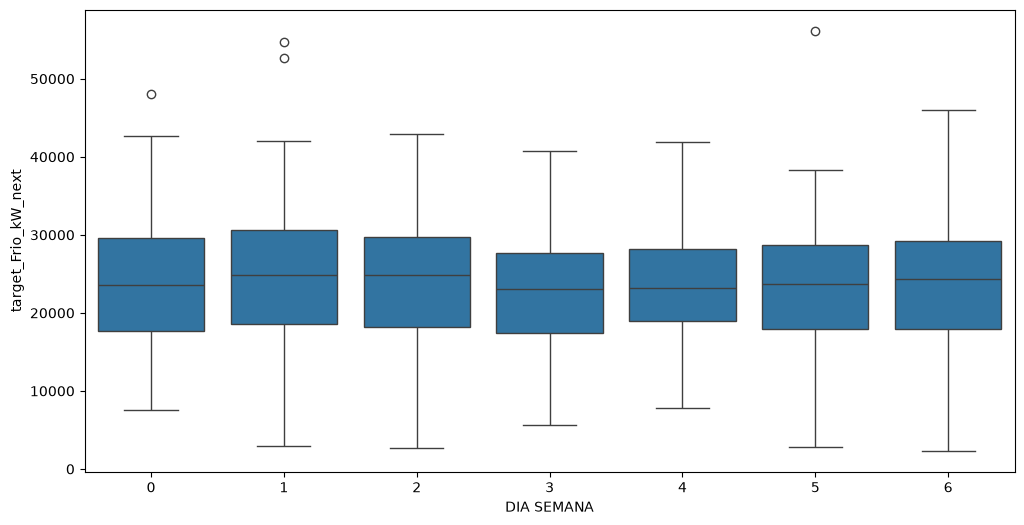

In [593]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="DIA SEMANA",y= "target_Frio_kW_next")


In [594]:
df_diario_sin_outliers["FIN DE SEMANA"] = df_diario_sin_outliers["DIA SEMANA"] >= 5 

<Axes: xlabel='FIN DE SEMANA', ylabel='target_Frio_kW_next'>

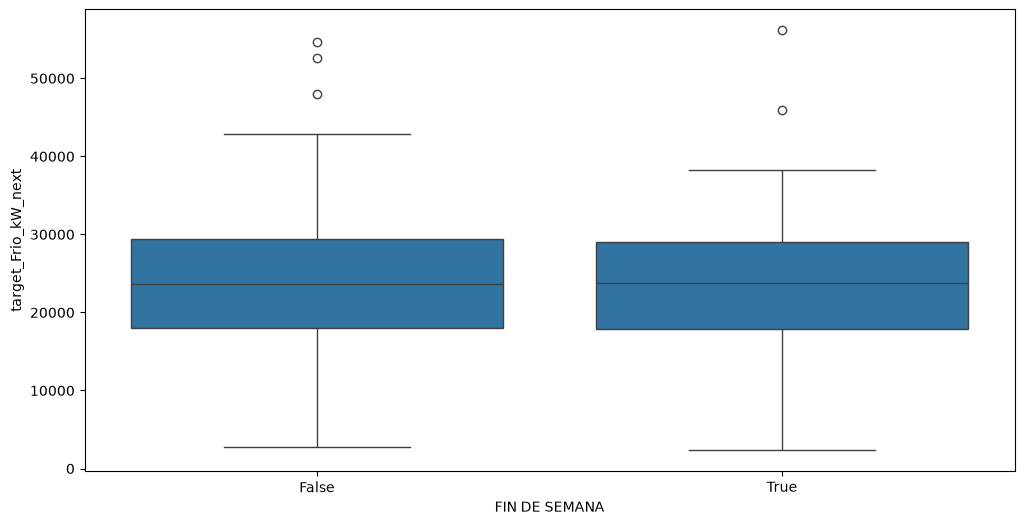

In [595]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="FIN DE SEMANA", y= "target_Frio_kW_next")


In [596]:
df_diario_sin_outliers = df_diario_sin_outliers.drop(columns="DIA SEMANA")

In [597]:
df_diario_sin_outliers = df_diario_sin_outliers.drop(columns="FIN DE SEMANA")

### Mes del año.

<Axes: xlabel='MES', ylabel='target_Frio_kW_next'>

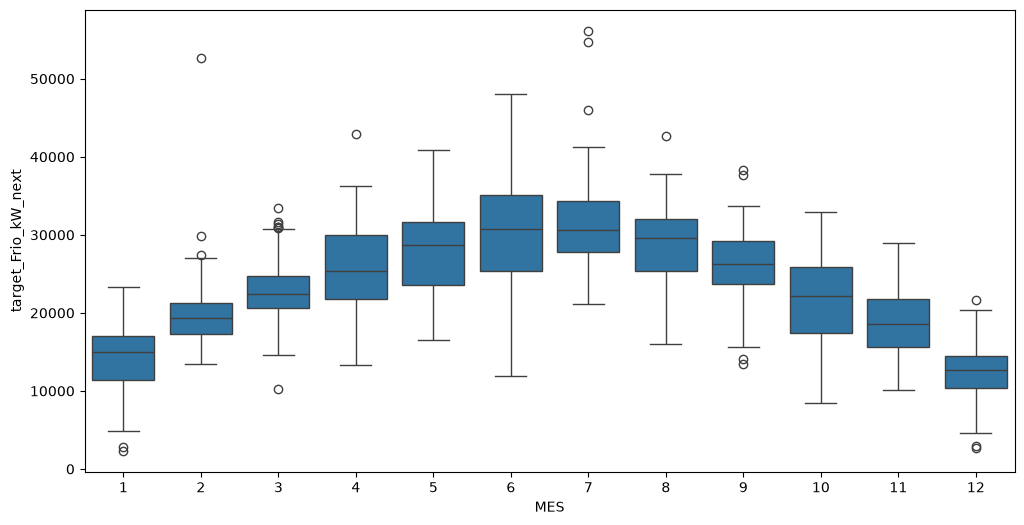

In [598]:
df_diario_sin_outliers["MES"] = df_diario_sin_outliers["DIA"].dt.month

plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="MES", y= "target_Frio_kW_next")

Estacionariedad, se mantiene la variable MES

In [599]:
df_diario_sin_outliers.columns

Index(['EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'Hl de Mosto', 'Hl Producido Bodega', 'Hl Cerveza Filtrada',
       'Hl Cerveza Envasada', 'Hl Cerveza Cocina', 'Elaboracion (Kw)',
       'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)', 'Frio (Kw)',
       'Agua Planta (Hl)', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Aire Producido (M3)', 'Totalizador Sistema Kaeser',
       'target_Frio_kW_next', 'Kw Mycom Mean', 'Kw Trafo Mean', 'DIA', 'MES'],
      dtype='str')

In [600]:
df_diario_sin_outliers["DIA DEL MES"] = df_diario_sin_outliers["DIA"].dt.day
df_diario_sin_outliers["SEMANA"] = (df_diario_sin_outliers["DIA DEL MES"] - 1 ) // 7 + 1

<Axes: xlabel='SEMANA', ylabel='target_Frio_kW_next'>

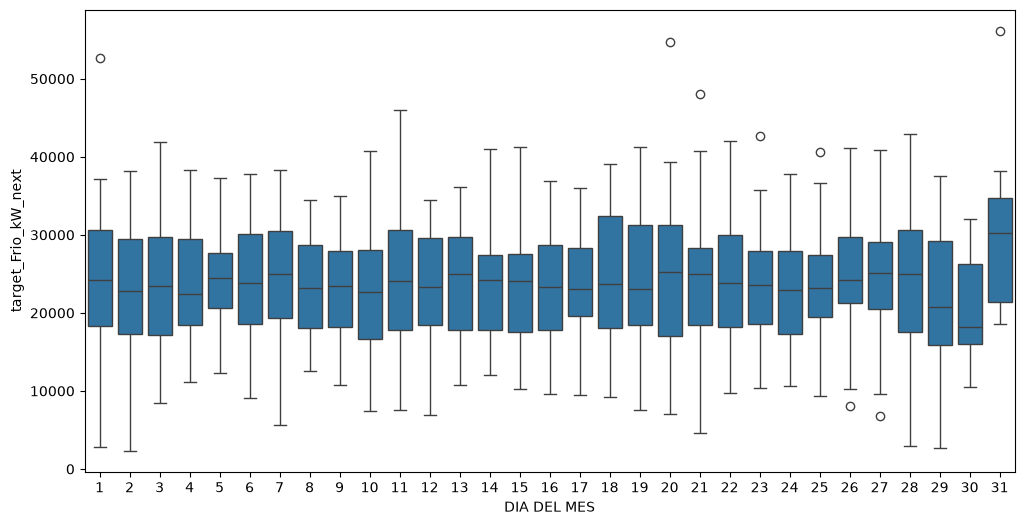

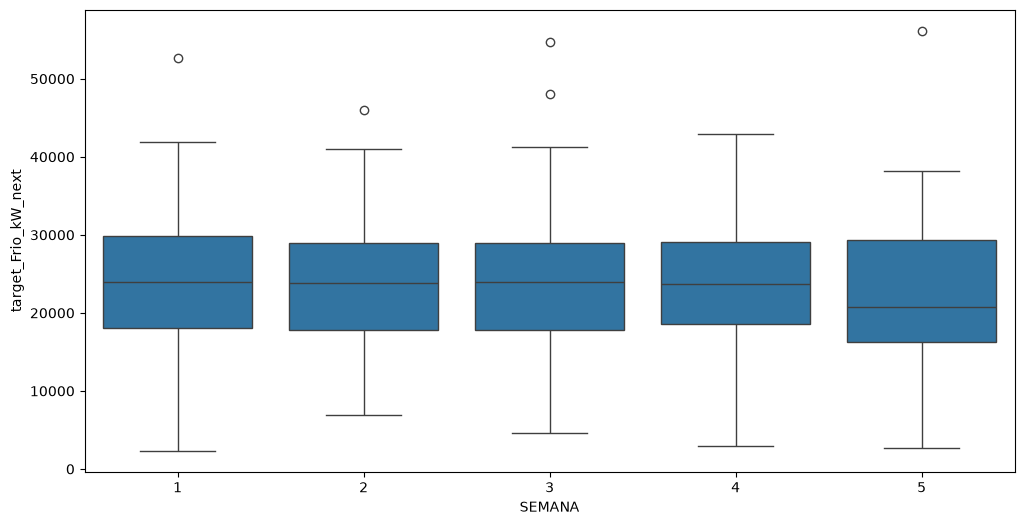

In [601]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="DIA DEL MES", y= "target_Frio_kW_next")
plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="SEMANA", y= "target_Frio_kW_next")

No se perciben cambios por semana ni día :)

### Variable de lag

In [602]:
fecha_pasada = pd.to_datetime(df_diario_sin_outliers["DIA"].shift(7))
fecha_actual = pd.to_datetime(df_diario_sin_outliers["DIA"])
diferencia_dia_pasado = fecha_actual - fecha_pasada

df_diario_sin_outliers['Frio lag last week'] = df_diario_sin_outliers['Frio (Kw)'].shift(7)
indices_a_borrar = df_diario_sin_outliers.index[diferencia_dia_pasado > pd.Timedelta(days=7)]
df_diario_sin_outliers.loc[indices_a_borrar, 'Frio lag last week'] = None 



### Promedio Móvil

In [603]:
#ts_data['rolling_mean_7'] = ts_data['passengers'].rolling(window=7).mean()
#ts_data['sin_day_of_year'] = np.sin(2 * np.pi * ts_data.index.dayofyear / 365)
#ts_data['cos_day_of_year'] = np.cos(2 * np.pi * ts_data.index.dayofyear / 365)

df_diario_sin_outliers["Prom movil Frio"] = df_diario_sin_outliers["Frio (Kw)"].rolling(window=7).mean()


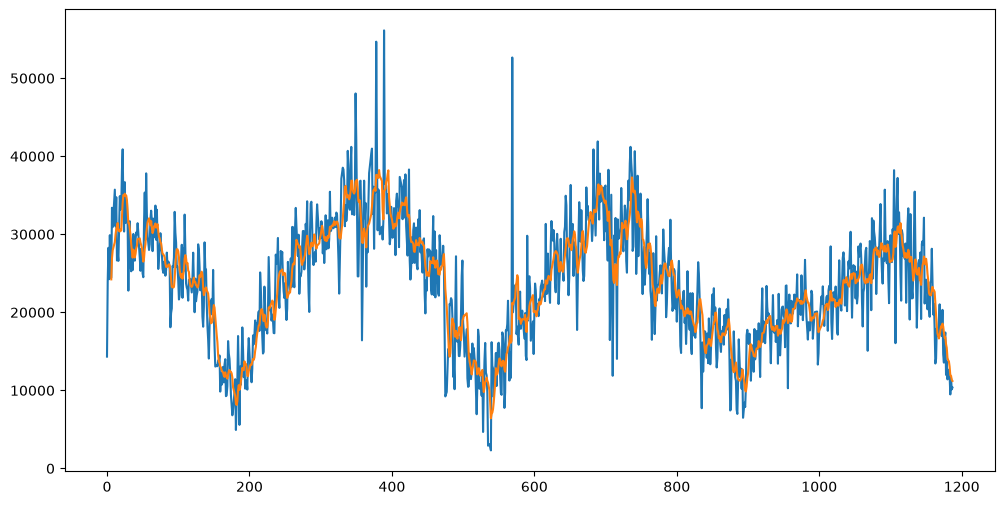

In [604]:
plt.figure(figsize=(12,6))
plt.plot(df_diario_sin_outliers["Frio (Kw)"])
plt.plot(df_diario_sin_outliers["Prom movil Frio"])

In [605]:
df_diario_sin_outliers['sin_month_of_year'] = np.sin(2 * np.pi * df_diario_sin_outliers["MES"] / 12)
df_diario_sin_outliers['cos_month_of_year'] = np.cos(2 * np.pi * df_diario_sin_outliers["MES"] / 12)


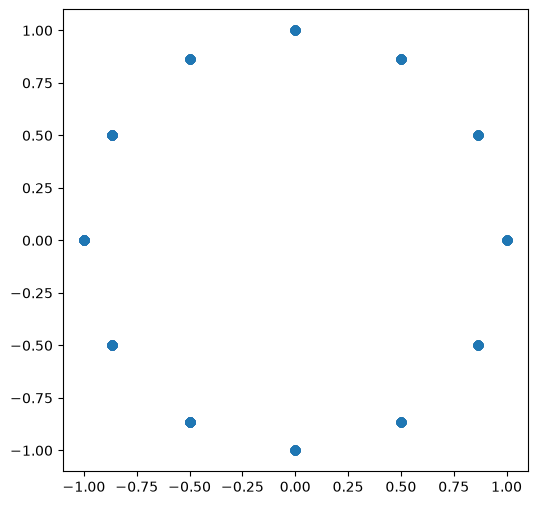

In [606]:
plt.figure(figsize=(6,6))
plt.scatter(df_diario_sin_outliers['sin_month_of_year'],df_diario_sin_outliers['cos_month_of_year'])


In [607]:
df_diario_sin_outliers.columns

Index(['EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'Hl de Mosto', 'Hl Producido Bodega', 'Hl Cerveza Filtrada',
       'Hl Cerveza Envasada', 'Hl Cerveza Cocina', 'Elaboracion (Kw)',
       'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)', 'Frio (Kw)',
       'Agua Planta (Hl)', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Aire Producido (M3)', 'Totalizador Sistema Kaeser',
       'target_Frio_kW_next', 'Kw Mycom Mean', 'Kw Trafo Mean', 'DIA', 'MES',
       'DIA DEL MES', 'SEMANA', 'Frio lag last week', 'Prom movil Frio',
       'sin_month_of_year', 'cos_month_of_year'],
      dtype='str')

### Creación de Variables mediante PolynomialFeature

In [608]:
var_def = ["Frio (Kw)","Produccion (Hl)","Vapor Elaboracion (Kg)","KW Cond 5. 6 y 9", "Temp Tq Intermedio"]

In [609]:
poly = PolynomialFeatures(degree=2, include_bias=False , interaction_only=False)

poly_features = poly.fit_transform(df_diario_sin_outliers[var_def])
poly_feature_names = poly.get_feature_names_out(var_def)

df_poly = pd.DataFrame(poly_features, columns=poly_feature_names)

print(f"\nCaracterísticas polinómicas generadas: {len(poly_feature_names)}")
print("Nuevas características (interacciones y cuadráticas):")

new_features = [name for name in poly_feature_names if name not in var_def]
display(new_features)

df_poly = df_poly[new_features].set_index(df_diario_sin_outliers.index)
df_diario_sin_outliers = pd.concat([df_diario_sin_outliers,df_poly],axis=1)


Características polinómicas generadas: 20
Nuevas características (interacciones y cuadráticas):


['Frio (Kw)^2',
 'Frio (Kw) Produccion (Hl)',
 'Frio (Kw) Vapor Elaboracion (Kg)',
 'Frio (Kw) KW Cond 5. 6 y 9',
 'Frio (Kw) Temp Tq Intermedio',
 'Produccion (Hl)^2',
 'Produccion (Hl) Vapor Elaboracion (Kg)',
 'Produccion (Hl) KW Cond 5. 6 y 9',
 'Produccion (Hl) Temp Tq Intermedio',
 'Vapor Elaboracion (Kg)^2',
 'Vapor Elaboracion (Kg) KW Cond 5. 6 y 9',
 'Vapor Elaboracion (Kg) Temp Tq Intermedio',
 'KW Cond 5. 6 y 9^2',
 'KW Cond 5. 6 y 9 Temp Tq Intermedio',
 'Temp Tq Intermedio^2']

## Pipeline de preprocesamiento

In [610]:
idx_outliers_target = df_diario[(df_diario["target_Frio_kW_next"] > 1e6)].index
df_diario = df_diario.drop(index=idx_outliers_target)

In [ ]:
df_diario["DIA"] = pd.to_datetime(df_diario["DIA"])
df_diario["MES"] = df_diario["DIA"].dt.month

fecha_pasada = pd.to_datetime(df_diario["DIA"].shift(7))
fecha_actual = pd.to_datetime(df_diario["DIA"])
diferencia_dia_pasado = fecha_actual - fecha_pasada

df_diario['Frio lag last week'] = df_diario['Frio (Kw)'].shift(7)
indices_a_borrar = df_diario.index[diferencia_dia_pasado > pd.Timedelta(days=7)]
df_diario.loc[indices_a_borrar, 'Frio lag last week'] = np.nan



fecha_pasada = pd.to_datetime(df_diario["DIA"].shift(2))
fecha_actual = pd.to_datetime(df_diario["DIA"])
diferencia_dia_pasado = fecha_actual - fecha_pasada

#lag plazo corto
df_diario['Frio lag 2 days'] = df_diario['Frio (Kw)'].shift(2)
indices_a_borrar = df_diario.index[diferencia_dia_pasado > pd.Timedelta(days=2)]
df_diario.loc[indices_a_borrar, 'Frio lag 2 days'] = np.nan 






df_diario["Prom movil Frio"] = df_diario["Frio (Kw)"].rolling(window=7).mean()

df_diario['sin_month_of_year'] = np.sin(2 * np.pi * df_diario["MES"] / 12)
df_diario['cos_month_of_year'] = np.cos(2 * np.pi * df_diario["MES"] / 12)

#ratios


df_diario['Ratio_Frio_Planta'] = (df_diario['Frio (Kw)'] / (df_diario['KW Gral Planta'] + 1e-5))
df_diario['Ratio_Frio_Movil'] = (df_diario['Frio (Kw)'] / (df_diario['Prom movil Frio'] + 1e-5))
df_diario['Ratio_Cond_Frio'] = (df_diario['KW Cond 5. 6 y 9'] / (df_diario['Frio (Kw)'] + 1e-5))
df_diario['Ratio_Vapor_Frio'] = (df_diario['Vapor Elaboracion (Kg)'] / (df_diario['Frio (Kw)'] + 1e-5))


In [612]:
df_diario = df_diario.drop(columns=["MES","DIA"])

In [613]:
X = df_diario.drop(columns="target_Frio_kW_next")
y = df_diario["target_Frio_kW_next"]

#train los más viejos, test los más nuevos
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state= 42, train_size=0.85, shuffle=False)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, random_state=42, train_size=0.70/0.85, shuffle=False) 

In [614]:
X_train.columns

Index(['EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'Hl de Mosto', 'Hl Producido Bodega', 'Hl Cerveza Filtrada',
       'Hl Cerveza Envasada', 'Hl Cerveza Cocina', 'Elaboracion (Kw)',
       'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)', 'Frio (Kw)',
       'Agua Planta (Hl)', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Aire Producido (M3)', 'Totalizador Sistema Kaeser', 'Kw Mycom Mean',
       'Kw Trafo Mean', 'Frio lag last week', 'Frio lag 2 days',
       'Prom movil Frio', 'sin_month_of_year', 'cos_month_of_year',
       'Ratio_Frio_Planta', 'Ratio_Frio_Movil', 'Ratio_Cond_Frio',
       'Ratio_Vapor_Frio'],
      dtype='str')

In [615]:
sk.set_config(transform_output='pandas')

In [616]:
X_no_out_tr = X_train.copy()
X_no_out_val = X_val.copy()
numericas = X_no_out_tr.select_dtypes(include=[np.number]).columns
for n in numericas:
    Q3 = X_no_out_tr[n].quantile(0.75)
    Q1 = X_no_out_tr[n].quantile(0.25)
    IQR = Q3 - Q1
    outliers = X_no_out_tr[(X_no_out_tr[n] < - 3 * IQR + Q1 ) | (X_no_out_tr[n] >  3 * IQR + Q3 )].index
    X_no_out_tr.loc[outliers,n] = None
    outliers_val = X_no_out_val[(X_no_out_val[n] < - 3 * IQR + Q1 ) | (X_no_out_val[n] >  3 * IQR + Q3 )].index
    X_no_out_val.loc[outliers_val, n] = None

features_creation = ColumnTransformer(
    transformers= [
        ("Poly", PolynomialFeatures(degree=2,include_bias=False, interaction_only=False), var_def) 
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

preprocesamiento = Pipeline(steps=[
    ("Winsorizer", Winsorizer(capping_method='iqr', tail='right', fold=1.5,missing_values="ignore")),
    ("Imputacion", KNNImputer(n_neighbors=10)),
    ("Features_creation", features_creation),
    ("Transformacion", PowerTransformer(method='yeo-johnson')),
    ("Escalado", RobustScaler())
])


Pipeline_forest = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', RandomForestRegressor())
])


Pipeline_forest.fit(X_no_out_tr, y_train)
y_pred = Pipeline_forest.predict(X_no_out_val)
score = Pipeline_forest.score(X_no_out_val, y_val)
print(f"R cuadrado: {score} ")


#error cuadrático medio
mse = ((y_val- y_pred) ** 2).mean()
rmse = float(mse ** 0.5)
mae = np.mean(np.abs(y_val - y_pred))
print(f"RMSE en Val: {rmse:.2f}")
print(f"MAE en Val: {mae:.2f}")

R cuadrado: 0.3875091047534188 
RMSE en Val: 2997.22
MAE en Val: 2388.33


In [617]:
features_forest = Pipeline_forest[-1].feature_names_in_
importancias_forest = Pipeline_forest[-1].feature_importances_

In [618]:
forest_features_importance = pd.DataFrame({"features" : features_forest, 
                                           "importancias" : importancias_forest})
forest_features_importance.sort_values(by="importancias", ascending=False)

,features,importancias
47,Prom movil Frio,0.222423
9,Frio (Kw) Temp Tq Intermedio,0.159844
40,Sala Maq (Kw),0.121953
0,Frio (Kw),0.104635
5,Frio (Kw)^2,0.066324
31,Servicios (Kw),0.043392
8,Frio (Kw) KW Cond 5. 6 y 9,0.015653
49,cos_month_of_year,0.014930
36,Tot Trasiego,0.014870
6,Frio (Kw) Produccion (Hl),0.013983


In [619]:
X_no_out_tr = X_train.copy()
X_no_out_val = X_val.copy()
numericas = X_no_out_tr.select_dtypes(include=[np.number]).columns
for n in numericas:
    Q3 = X_no_out_tr[n].quantile(0.75)
    Q1 = X_no_out_tr[n].quantile(0.25)
    IQR = Q3 - Q1
    outliers = X_no_out_tr[(X_no_out_tr[n] < - 3 * IQR + Q1 ) | (X_no_out_tr[n] >  3 * IQR + Q3 )].index
    X_no_out_tr.loc[outliers,n] = None
    outliers_val = X_no_out_val[(X_no_out_val[n] < - 3 * IQR + Q1 ) | (X_no_out_val[n] >  3 * IQR + Q3 )].index
    X_no_out_val.loc[outliers_val, n] = None
    
features_creation = ColumnTransformer(
    transformers= [
        ("Poly", PolynomialFeatures(degree=2,include_bias=False, interaction_only=False), var_def) 
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)


preprocesamiento = Pipeline(steps=[
    ("Winsorizer", Winsorizer(capping_method='iqr', tail='right', fold=1.5,missing_values="ignore")),
    ("Imputacion", KNNImputer(n_neighbors=10)),
    ("Features_creation", features_creation),
    ("Transformacion", PowerTransformer(method='yeo-johnson')),
    ("Escalado", RobustScaler())
])


Pipeline_lasso = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', LassoCV())
])

Pipeline_lasso.set_params(modelo__cv=5, modelo__random_state=42)

Pipeline_lasso.fit(X_no_out_tr, y_train)
y_pred = Pipeline_lasso.predict(X_no_out_val)
score = Pipeline_lasso.score(X_no_out_val, y_val)
print(f"R cuadrado: {score} ")


#error cuadrático medio
mse = ((y_val- y_pred) ** 2).mean()
rmse = float(mse ** 0.5)
mae = np.mean(np.abs(y_val - y_pred))
print(f"RMSE en Val: {rmse:.2f}")
print(f"MAE en Val: {mae:.2f}")

R cuadrado: 0.40946160536734044 
RMSE en Val: 2943.02
MAE en Val: 2275.14


In [620]:
features_lasso = Pipeline_lasso[-1].feature_names_in_
importancias_lasso = Pipeline_lasso[-1].coef_
lasso_features_importance = pd.DataFrame({"features" : features_lasso, "importancias" : importancias_lasso})
lasso_features_importance.sort_values(by="importancias", ascending=False)

,features,importancias
38,KW Gral Planta,2489.187584
47,Prom movil Frio,2009.640020
8,Frio (Kw) KW Cond 5. 6 y 9,1379.650127
50,Ratio_Frio_Planta,626.217935
5,Frio (Kw)^2,561.910750
7,Frio (Kw) Vapor Elaboracion (Kg),502.632915
45,Frio lag last week,471.572484
43,Kw Mycom Mean,469.559625
9,Frio (Kw) Temp Tq Intermedio,419.490451
30,Envasado (Kw),395.424401


In [566]:
# preprocesamiento = Pipeline(steps=[
#     ("Winsorizer", Winsorizer(capping_method='iqr', tail='right', fold=1.5,missing_values="ignore").set_output(transform="pandas")),
#     ("Transformacion", PowerTransformer(method='yeo-johnson').set_output(transform="pandas")),
#     ("Escalado", RobustScaler().set_output(transform="pandas")),
#     ("Imputacion", KNNImputer(n_neighbors=10).set_output(transform="pandas")),
#     ("Features_creation", features_creation.set_output(transform="pandas"))  
# ])


param_grid = [{
    'preprocesamiento__Winsorizer': [Winsorizer(capping_method='quantiles',tail='both',missing_values='ignore'), Winsorizer(capping_method='iqr', tail='right', fold=1.5,missing_values="ignore").set_output(transform="pandas")],
    'preprocesamiento__Escalado': [StandardScaler(), RobustScaler()],
    'preprocesamiento__Transformacion': [PowerTransformer(method='yeo-johnson'), 'passthrough'],
    'preprocesamiento__Imputacion__n_neighbors': [1,3,5,7,10],
    'preprocesamiento__Features_creation' : [features_creation, 'passthrough']
}]

particion = TimeSeriesSplit(n_splits=5)

grid_pipe_lasso = GridSearchCV(Pipeline_lasso, param_grid,scoring='neg_mean_absolute_error', cv= particion)

grid_pipe_lasso.fit(X_no_out_tr, y_train)

y_pred = grid_pipe_lasso.predict(X_no_out_val)
score_grid = grid_pipe_lasso.score(X_no_out_val, y_val)
print(f"MAE: {score_grid} ")

grid_pipe_lasso.best_params_



c:\Users\ireni\miniconda3\envs\cervecera_env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.729322e+05, tolerance: 1.583e+05
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\ireni\miniconda3\envs\cervecera_env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.924715e+05, tolerance: 1.583e+05
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\ireni\miniconda3\envs\cervecera_env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the feat

MAE: -2348.8017336558682 


{'preprocesamiento__Escalado': StandardScaler(),
 'preprocesamiento__Features_creation': 'passthrough',
 'preprocesamiento__Imputacion__n_neighbors': 1,
 'preprocesamiento__Transformacion': PowerTransformer(),
 'preprocesamiento__Winsorizer': Winsorizer(capping_method='iqr', fold=1.5, missing_values='ignore')}

In [567]:
grid_pipe_forest = GridSearchCV(Pipeline_forest, param_grid,scoring='neg_mean_absolute_error', cv=particion)

grid_pipe_forest.fit(X_no_out_tr, y_train)

y_pred = grid_pipe_forest.predict(X_no_out_val)
score_grid = grid_pipe_forest.score(X_no_out_val, y_val)
print(f"MAE: {score_grid} ")

grid_pipe_forest.best_params_


KeyboardInterrupt: 

### Variables seleccionadas:

## Por parte de Lasso se obtuvo : 


Frio (Kw)	        2980.485952

cos_month_of_year	-2624.231068

KW Gral Planta 	    1961.917684

Prom movil Frio	    1938.091334

KW Cond 5. 6 y 9	941.363571

EE Frio / Hl	-594.526026

Temp Tq Intermedio	581.231264

Frio lag last week	493.976077

Hl Cerveza Filtrada	-410.614397

Agua Cond REC	    333.168899

Sala Maq (Kw)	    317.436525

Bodega (Kw)^2	-228.580113

Servicios (Kw)^2	-137.612878

Vapor Elaboracion (Kg)	106.456587

Elaboracion (Kw)^2	-80.325067

Tot  Trasiego	43.283180

Envasado (Kw)	36.980210

Gas Planta (Mj)	32.428585

Agua Planta (Hl)	6.659103


## Por parte de Random Forest se obtuvo : 

Prom movil Frio	0.247896

Frio (Kw)	    0.224387

Sala Maq (Kw)	0.163321

Servicios (Kw)	0.066490

cos_month_of_year	0.022269

KW Gral Planta	0.021410

Kw Mycom Mean	0.017125

Tot  Trasiego	0.014272

EE Frio / Hl	0.012778

Frio lag last week	0.012667

KW Cond 5. 6 y 9	0.010549

Agua Planta (Hl)	0.010381

Agua Cond REC	0.009854

Temp Tq Intermedio	0.009198

Servicios (Kw) Planta (Kw)	0.008942

KW Bba Glicol Bod	0.008332

Vapor Elaboracion (Kg)	0.008295

KW Bba Glicol Sala MAq	0.008069

Hl Cerveza Filtrada	0.006488

Servicios (Kw)^2	0.006283

Totalizador_Bodega	0.006162

Produccion (Hl)	0.005904

Hl Producido Bodega	0.005721

Gas Planta (Mj)	0.005486

## Variables seleccionadas: 

En base a los resultados obtenidos en la selección mediante Lasso y RandomForest, se han seleccionado las siguientes varibales:

* Frio (Kw): 

* cos_month_of_year:

* Prom movil Frio: 

* KW Gral Planta: 

* KW Cond 5. 6 y 9:

* EE Frio / Hl:

* Temp Tq Intermedio:

* Frio lag last week:

* Sala Maq (Kw):

* Kw Mycom Mean:

* Hl Cerveza Filtrada:

* Servicios (Kw):

* Tot  Trasiego:

* Agua Cond REC:

* Vapor Elaboracion (Kg):
